
# Analyse de l'implication des gènes dans les paires de clusters

1. **La fréquence d'apparition de chaque gène** à travers l'ensemble des 444 paires
   (un gène peut apparaître dans plusieurs paires).
2. **La proportion de paires "auto-appariées"** (même gène des deux côtés de la paire,
   si ce cas existe dans ton jeu de données).
3. **Une vue réseau** (graph) pour visualiser quels gènes sont les plus connectés
   entre eux à travers les paires.
4. **Comparaison clustering & paires** pour découvrir comment la fréquence d'apparition
   d'un gène impacte le clustering effectué derrière.


In [14]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import networkx as nx
from itertools import combinations
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
sns.set_theme(style="whitegrid")


## Configuration

In [15]:

CONFIG = {
    "csv_path": "Données/lamme_training.csv",   # chemin vers ton fichier
    "sep": ",",                          # séparateur (";" si export Excel FR)
    "gene1_col": "Gene1",               # nom de la 1ère colonne de gène/protéine
    "gene2_col": "Gene2",               # nom de la 2ème colonne de gène/protéine
    "cluster_col": None,                 # ex: "cluster_mimiSBM" si tu as déjà une colonne de cluster, sinon None
}

df = pd.read_csv(CONFIG["csv_path"], sep=CONFIG["sep"])
print(df.shape)
df.head()


(444, 30)


,Gene1,Gene2,Family_Size,Classification,PPI_Interactant_G1,PPI_Interactant_G2,PPI_Intersection,PPI_Union,PPI_Jaccard,Pfam_G1,...,TE_Coverage_G1,TE_Density_G1,TE_Number_G1,TE_Coverage_G2,TE_Density_G2,TE_Number_G2,TE_Env_G1,TE_Env_G2,TE_Env_Pair,TE_Env_Class
0,AT1G01030,AT2G46870,4,1.0,6.0,4.0,1.0,9.0,11.111111,1.0,...,1.318826,0.167056,1.0,5.777292,0.193424,1.0,TE-free,TE-free,TE-free_TE-free,free
1,AT1G01030,AT4G01500,4,1.0,11.0,4.0,1.0,14.0,7.142857,1.0,...,1.318826,0.167056,1.0,29.346681,0.745712,3.0,TE-rich,TE-free,TE-free_TE-rich,half
2,AT1G01060,AT2G46830,2,0.0,23.0,21.0,12.0,32.0,37.500000,1.0,...,0.000000,0.000000,0.0,0.000000,0.000000,0.0,TE-free,TE-free,TE-free_TE-free,free
3,AT1G01120,AT1G04220,17,1.0,8.0,7.0,1.0,14.0,7.142857,3.0,...,15.273775,0.200080,1.0,0.000000,0.000000,0.0,TE-free,TE-poor,TE-free_TE-poor,half
4,AT1G01120,AT4G34520,17,1.0,0.0,7.0,0.0,7.0,NaN,3.0,...,15.273775,0.200080,1.0,0.000000,0.000000,0.0,TE-free,TE-poor,TE-free_TE-poor,half



## 1. Fréquence d'apparition de chaque gène à travers les 444 paires

On empile les deux colonnes de gènes pour compter combien de fois chaque
gène apparaît, tous côtés de paire confondus.


In [16]:
g1 = df[CONFIG["gene1_col"]].astype(str)
g2 = df[CONFIG["gene2_col"]].astype(str)

all_genes = pd.concat([g1, g2], ignore_index=True)
gene_counts = all_genes.value_counts().rename_axis("gene").reset_index(name="n_occurrences")

print(f"Nombre de gènes uniques impliqués : {gene_counts.shape[0]}")
print(f"Nombre total de paires : {df.shape[0]}")
gene_counts.head(20)


Nombre de gènes uniques impliqués : 700
Nombre total de paires : 444


,gene,n_occurrences
0,AT5G64740,6
1,AT3G49700,5
2,AT5G07990,5
3,AT1G23090,4
4,AT1G69120,4
5,AT1G78000,4
6,AT2G22540,4
7,AT2G22630,4
8,AT2G40890,4
9,AT2G45660,4


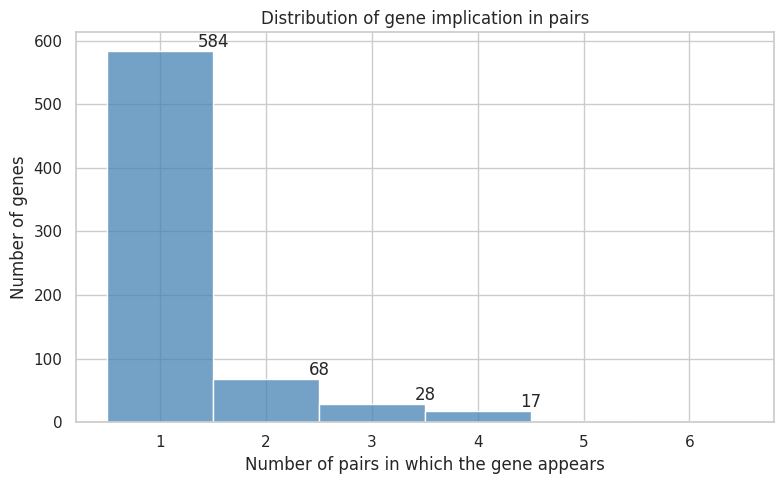

In [28]:
# Distribution du nombre d'occurrences par gène
plt.figure(figsize=(8, 5))
ax = sns.histplot(gene_counts["n_occurrences"], bins=range(1, gene_counts["n_occurrences"].max() + 2),
                  discrete=True, color="steelblue")
counts_by_occurrence = gene_counts["n_occurrences"].value_counts()
for occurrence in range(1, 5):
    n_genes = counts_by_occurrence.get(occurrence, 0)
    ax.text(occurrence + 0.5, n_genes, str(n_genes), ha="center", va="bottom")
plt.xlabel("Number of pairs in which the gene appears")
plt.ylabel("Number of genes")
plt.title("Distribution of gene implication in pairs")
plt.tight_layout()
plt.savefig("Plots/Distribution_occurrences_genes.png", dpi=300)
plt.show()


In [18]:
print(f"Nombre de gènes impliqués dans seulement 1 paire : {gene_counts[gene_counts['n_occurrences'] == 1].shape[0]}")
print(f"Nombre de gènes impliqués dans 2 paires : {gene_counts[gene_counts['n_occurrences'] == 2].shape[0]}")
print(f"Nombre de gènes impliqués dans 3 paires : {gene_counts[gene_counts['n_occurrences'] == 3].shape[0]}")
print(f"Nombre de gènes impliqués dans 4 paires : {gene_counts[gene_counts['n_occurrences'] == 4].shape[0]}")

Nombre de gènes impliqués dans seulement 1 paire : 584
Nombre de gènes impliqués dans 2 paires : 68
Nombre de gènes impliqués dans 3 paires : 28
Nombre de gènes impliqués dans 4 paires : 17


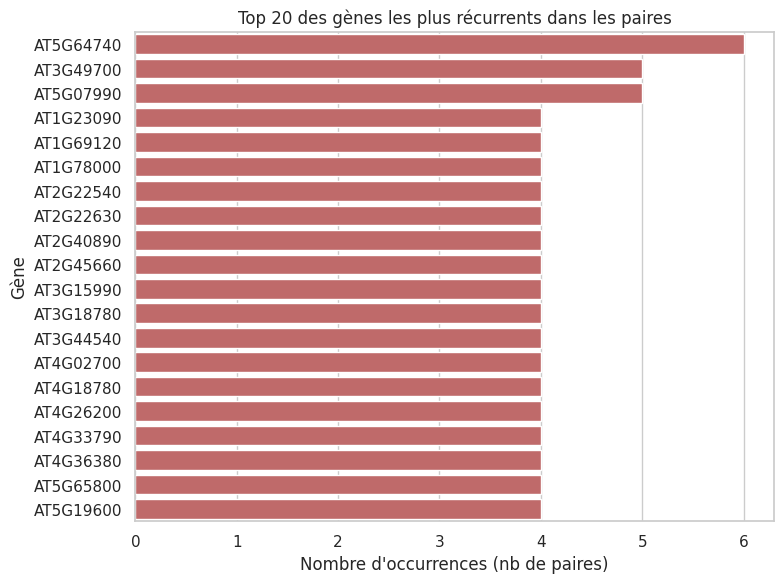

In [19]:
# Top 20 des gènes les plus "impliqués" (hubs)
plt.figure(figsize=(8, 6))
top20 = gene_counts.head(20)
sns.barplot(data=top20, y="gene", x="n_occurrences", color="indianred")
plt.xlabel("Nombre d'occurrences (nb de paires)")
plt.ylabel("Gène")
plt.title("Top 20 des gènes les plus récurrents dans les paires")
plt.tight_layout()
plt.show()



## 2. Paires "auto-appariées" (même gène des deux côtés)

Si dans ton jeu de données une ligne peut avoir `Gene_1 == Gene_2`
(diagonale de la matrice d'adjacence), on quantifie ça ici.


In [20]:
self_pairs = df[g1 == g2]
n_self = self_pairs.shape[0]
pct_self = 100 * n_self / df.shape[0]

print(f"Paires auto-appariées (même gène) : {n_self} / {df.shape[0]} ({pct_self:.1f} %)")
self_pairs.head()


Paires auto-appariées (même gène) : 0 / 444 (0.0 %)


,Gene1,Gene2,Family_Size,Classification,PPI_Interactant_G1,PPI_Interactant_G2,PPI_Intersection,PPI_Union,PPI_Jaccard,Pfam_G1,...,TE_Coverage_G1,TE_Density_G1,TE_Number_G1,TE_Coverage_G2,TE_Density_G2,TE_Number_G2,TE_Env_G1,TE_Env_G2,TE_Env_Pair,TE_Env_Class



## 3. Vue réseau : quels gènes sont connectés entre eux ?

Chaque paire devient une arête d'un graphe. On peut ainsi repérer les gènes
les plus "centraux" (degré élevé = impliqué dans beaucoup de paires distinctes),
ce qui est complémentaire au simple comptage d'occurrences (un gène peut apparaître
plusieurs fois mais toujours avec le même partenaire).


In [21]:
G = nx.from_pandas_edgelist(df, source=CONFIG["gene1_col"], target=CONFIG["gene2_col"])

print(f"Nombre de nœuds (gènes uniques) : {G.number_of_nodes()}")
print(f"Nombre d'arêtes (paires uniques, doublons fusionnés) : {G.number_of_edges()}")

degree_df = pd.DataFrame(G.degree(), columns=["gene", "degree"]).sort_values("degree", ascending=False)
degree_df.head(20)


Nombre de nœuds (gènes uniques) : 700
Nombre d'arêtes (paires uniques, doublons fusionnés) : 444


,gene,degree
628,AT5G64740,6
11,AT3G49700,5
399,AT5G07990,5
293,AT2G22540,4
137,AT3G18780,4
13,AT5G65800,4
169,AT1G23090,4
170,AT1G78000,4
171,AT3G15990,4
172,AT4G02700,4


In [22]:
# Comparaison occurrences (comptage brut) vs degree (nb de partenaires distincts)
comparison = gene_counts.merge(degree_df, on="gene", how="left")
comparison["n_duplicate_partners"] = comparison["n_occurrences"] - comparison["degree"]

# Un gène avec n_occurrences élevé mais degree faible = toujours apparié aux mêmes partenaires
comparison.sort_values("n_occurrences", ascending=False).head(20)


,gene,n_occurrences,degree,n_duplicate_partners
0,AT5G64740,6,6,0
1,AT3G49700,5,5,0
2,AT5G07990,5,5,0
3,AT1G23090,4,4,0
4,AT1G69120,4,4,0
5,AT1G78000,4,4,0
6,AT2G22540,4,4,0
7,AT2G22630,4,4,0
8,AT2G40890,4,4,0
9,AT2G45660,4,4,0


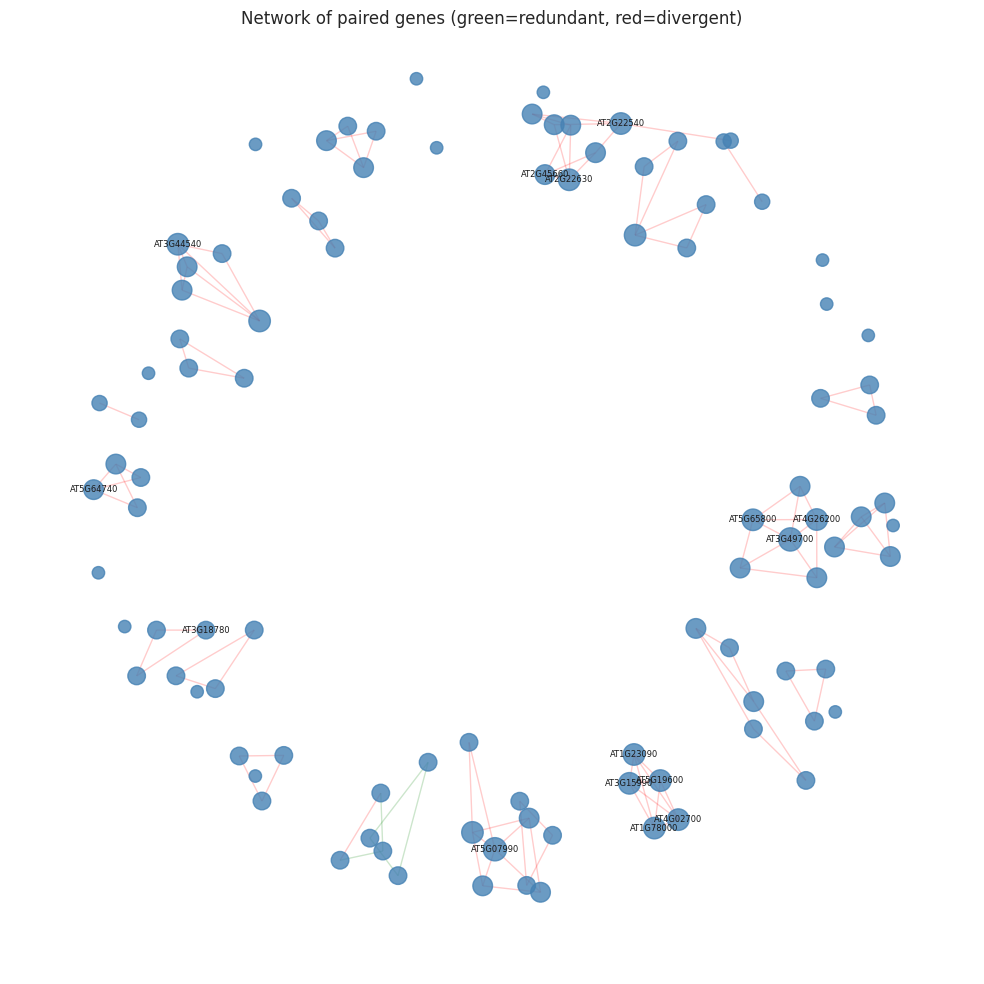

In [23]:
# Charger les labels redondant/divergent depuis Y_train_clean.csv
Y_train = pd.read_csv('Données/Y_train_clean.csv')
df_with_labels = df.copy()
df_with_labels['classification'] = Y_train['Classification'].values

# Visualisation du graphe (sous-échantillon si trop dense pour rester lisible)
plt.figure(figsize=(10, 10))

if G.number_of_nodes() > 100:
    # on ne garde que les gènes les plus connectés pour la lisibilité
    top_nodes = degree_df.head(100)["gene"]
    G_sub = G.subgraph(top_nodes)
else:
    G_sub = G

pos = nx.spring_layout(G_sub, seed=42, k=0.3)
node_sizes = [80 + 40 * G_sub.degree(n) for n in G_sub.nodes()]

# Ajouter des couleurs aux arêtes entre 2 paires de gènes avec du vert quand c'est redondant et du rouge quand c'est divergent
# Récupérer information redondant et divergent dans 'Données/Y_train_clean.csv' pour chaque paire de gènes
edge_colors = []
for u, v in G_sub.edges():
    pair_df = df_with_labels[((df_with_labels[CONFIG["gene1_col"]] == u) & (df_with_labels[CONFIG["gene2_col"]] == v)) |
                 ((df_with_labels[CONFIG["gene1_col"]] == v) & (df_with_labels[CONFIG["gene2_col"]] == u))]
    if not pair_df.empty:
        classification = pair_df.iloc[0]["classification"]
        if classification == 0:
            # Ajout de la couleur verte à la position correspondante au couple de gènes dans edge_colors
            edge_colors.append("green")  # redondant
        elif classification == 1:
            # Ajout de la couleur rouge à la position correspondante au couple de gènes dans edge_colors
            edge_colors.append("red")    # divergent
        else:
            edge_colors.append("gray")
    else:
        edge_colors.append("gray")

# Visualisation du graphe en ajoutant les couleurs aux arêtes et en affichant les labels des gènes les plus connectés
nx.draw_networkx_edges(G_sub, pos, edge_color=edge_colors, alpha=0.2)
nx.draw_networkx_nodes(G_sub, pos, node_size=node_sizes, node_color="steelblue", alpha=0.8)
# Affichage des noms des 15 gènes les plus connectés
nx.draw_networkx_labels(G_sub, pos, font_size=6,
                         labels={n: n for n in degree_df.head(15)["gene"]})

plt.title("Network of paired genes (green=redundant, red=divergent)")
plt.axis("off")
plt.tight_layout()
plt.savefig("Plots/graph_genes.png", dpi=300)
plt.show()

## 4. Comparaison clustering et gènes impliqués dans plusieurs paires

In [24]:
def build_family_adjacency_matrices(X_scaled, descriptor_families, n_init=20, random_state=42):
    """
    Applique un clustering KMeans par famille de descripteurs et
    retourne les matrices d'adjacence associées.
    """
    family_adjacency_matrices = {}

    for family_name, cols in descriptor_families.items():
        if family_name == "Pfam":
            optimal_k = 5
        elif family_name == "PPI":
            optimal_k = 5
        elif family_name == "Ks_et_Ka":
            optimal_k = 2
        else:
            optimal_k = 3

        X_family = X_scaled[cols]

        kmeans_family = KMeans(
            n_clusters=optimal_k,
            n_init=n_init,
            random_state=random_state,
            init="k-means++"
        )
        labels_family = kmeans_family.fit_predict(X_family)

        Z_family = pd.DataFrame(X_family, columns=X_family.columns)
        Z_family["Cluster"] = labels_family

        Z_family_binary = pd.get_dummies(Z_family["Cluster"], prefix="Cluster").astype(int)

        adjacency_matrix_family = Z_family_binary.values @ Z_family_binary.values.T
        adjacency_matrix_family = adjacency_matrix_family - np.diag(np.diag(adjacency_matrix_family))

        family_adjacency_matrices[family_name] = adjacency_matrix_family

    return family_adjacency_matrices


def analyze_shared_gene_effect(pairs_df, family_adjacency_matrices):
    """
    Compare le fait de partager un gène avec la probabilité d'être
    dans le même cluster pour chaque famille.
    """
    gene1 = pairs_df["Gene1"].astype(str)
    gene2 = pairs_df["Gene2"].astype(str)

    n = len(pairs_df)
    gene_sets = [{gene1.iloc[i], gene2.iloc[i]} for i in range(n)]

    same_gene_matrix = np.zeros((n, n), dtype=int)
    for i, j in combinations(range(n), 2):
        if gene_sets[i] & gene_sets[j]:
            same_gene_matrix[i, j] = 1
            same_gene_matrix[j, i] = 1

    triu_idx = np.triu_indices(n, k=1)
    shared_gene_flags = same_gene_matrix[triu_idx]

    results = []

    for family_name, adjacency_matrix_family in family_adjacency_matrices.items():
        same_cluster_flags = (adjacency_matrix_family[triu_idx] > 0).astype(int)

        n_shared = shared_gene_flags.sum()
        n_not_shared = (shared_gene_flags == 0).sum()

        n_shared_and_clustered = ((shared_gene_flags == 1) & (same_cluster_flags == 1)).sum()
        n_not_shared_and_clustered = ((shared_gene_flags == 0) & (same_cluster_flags == 1)).sum()

        prop_if_shared = n_shared_and_clustered / n_shared if n_shared > 0 else np.nan
        prop_if_not_shared = n_not_shared_and_clustered / n_not_shared if n_not_shared > 0 else np.nan
        ratio = prop_if_shared / prop_if_not_shared if prop_if_not_shared else np.nan

        contingency = np.array([
            [n_shared_and_clustered, n_shared - n_shared_and_clustered],
            [n_not_shared_and_clustered, n_not_shared - n_not_shared_and_clustered],
        ])

        # vérifier qu'il n'y a pas de valeur en dessous de 5 dans la table de contingence pour le test du chi2
        if np.any(contingency < 5):
            p_value = np.nan
        else:
            _, p_value, _, _ = chi2_contingency(contingency)

        results.append({
            "family": family_name,
            "n_shared_gene": n_shared,
            "prop_same_cluster_gene_commun": prop_if_shared,
            "prop_same_cluster_no_gene_commun": prop_if_not_shared,
            "ratio_influence": ratio,
            "chi2_p_value": p_value,
        })

    return pd.DataFrame(results).sort_values("ratio_influence", ascending=False)


In [25]:
# ------------------------------------------------------------
# Utilisation
# ------------------------------------------------------------
X_train = pd.read_csv('Données/X_train_clean.csv')
num_cols = X_train.select_dtypes(include=['float64', 'int64']).columns
X_num = X_train[num_cols]

descriptor_families = {
    'PPI': ['PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean'],
    'Pfam': ['Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Pfam_Asymmetry', 'Pfam_Mean', 'Family_Size'],
    'Ks_et_Ka': ['Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Expression_Data_Missing', 'Distance'],
    'TE': ['TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 
           'TE_Number_Mean', 'TE_Density_Asymmetry', 'TE_Density_Mean', 'TE_Env_Match'],}

# Standardiser les données
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_num),
    columns=X_num.columns
)
pairs_df = pd.read_csv("Données/lamme_training.csv").reset_index(drop=True)

n_init = 20
random_state = 42
family_adjacency_matrices = build_family_adjacency_matrices(
    X_scaled=X_scaled,
    descriptor_families=descriptor_families,
    n_init=n_init,
    random_state=random_state
)

results_df = analyze_shared_gene_effect(pairs_df, family_adjacency_matrices)
results_df

,family,n_shared_gene,prop_same_cluster_gene_commun,prop_same_cluster_no_gene_commun,ratio_influence,chi2_p_value
1,Pfam,289,0.854671,0.521034,1.640338,1.665801e-29
0,PPI,289,0.844291,0.590911,1.428794,3.605911e-18
2,Ks_et_Ka,289,0.768166,0.555442,1.382981,5.655910e-13
3,TE,289,0.650519,0.494090,1.316600,1.503236e-07


In [26]:
# import pandas as pd
# import numpy as np
# from itertools import combinations
# from scipy.stats import chi2_contingency
# from sklearn.cluster import KMeans
# from sklearn.preprocessing import StandardScaler

# # ============================================================
# # Chargement des deux datasets
# # ============================================================
# PAIR_DATA_PATH = "Données/lamme_training.csv"
# X_DATA_PATH = "Données/X_train_clean.csv"

# pairs_df = pd.read_csv(PAIR_DATA_PATH).reset_index(drop=True)
# X_df = pd.read_csv(X_DATA_PATH).reset_index(drop=True)

# print(f"pairs_df shape: {pairs_df.shape}")
# print(f"X_df shape: {X_df.shape}")

# assert pairs_df.shape[0] == X_df.shape[0], (
#     "Le nombre de lignes ne correspond pas entre lamme_training.csv et X_train_clean.csv"
# )

# # Colonnes de gènes dans lamme_training.csv
# GENE_COLS = {"gene1": "Gene1", "gene2": "Gene2"}

# gene1 = pairs_df[GENE_COLS["gene1"]].astype(str)
# gene2 = pairs_df[GENE_COLS["gene2"]].astype(str)

# # ------------------------------------------------------------
# # 1. Préparation des features pour le clustering
# # ------------------------------------------------------------
# X_num = X_df.select_dtypes(include=["number", "bool"]).copy()
# X_num = X_num.astype(float).fillna(0)

# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X_num)

# # ------------------------------------------------------------
# # 2. Clustering sur X_train_clean
# # ------------------------------------------------------------
# K_CLUSTERS = 2  # à adapter si besoin
# kmeans = KMeans(n_clusters=K_CLUSTERS, random_state=42, n_init=20)
# cluster_labels = kmeans.fit_predict(X_scaled)

# cluster_sizes = pd.Series(cluster_labels).value_counts().sort_index()
# print("Tailles des clusters :")
# print(cluster_sizes)

# # Matrice de même-cluster : same_cluster_matrix[i, j] = 1 si les lignes i et j sont dans le même cluster
# same_cluster_matrix = (cluster_labels[:, None] == cluster_labels[None, :]).astype(int)

# # ------------------------------------------------------------
# # 3. Fréquence d'implication de chaque gène
# # ------------------------------------------------------------
# n = len(pairs_df)
# all_genes = pd.concat([gene1, gene2], ignore_index=True)
# gene_counts = all_genes.value_counts().rename_axis("gene").reset_index(name="n_occurrences")
# print("Top 20 des gènes les plus impliqués :")
# print(gene_counts.head(20))

# # ------------------------------------------------------------
# # 4. Matrice "même gène" : un 1 si les deux paires partagent un gène
# # ------------------------------------------------------------
# gene_sets = [{gene1.iloc[i], gene2.iloc[i]} for i in range(n)]

# same_gene_matrix = np.zeros((n, n), dtype=int)
# for i, j in combinations(range(n), 2):
#     if gene_sets[i] & gene_sets[j]:
#         same_gene_matrix[i, j] = 1
#         same_gene_matrix[j, i] = 1

# triu_idx = np.triu_indices(n, k=1)
# shared_gene_flags = same_gene_matrix[triu_idx]
# same_cluster_flags = same_cluster_matrix[triu_idx]

# # ------------------------------------------------------------
# # 5. Analyse : partage de gène vs même cluster
# # ------------------------------------------------------------
# results = []

# n_shared = shared_gene_flags.sum()
# n_not_shared = (shared_gene_flags == 0).sum()

# n_shared_and_clustered = ((shared_gene_flags == 1) & (same_cluster_flags == 1)).sum()
# n_not_shared_and_clustered = ((shared_gene_flags == 0) & (same_cluster_flags == 1)).sum()

# prop_if_shared = n_shared_and_clustered / n_shared if n_shared > 0 else np.nan
# prop_if_not_shared = n_not_shared_and_clustered / n_not_shared if n_not_shared > 0 else np.nan
# ratio = prop_if_shared / prop_if_not_shared if prop_if_not_shared else np.nan

# contingency = np.array([
#     [n_shared_and_clustered, n_shared - n_shared_and_clustered],
#     [n_not_shared_and_clustered, n_not_shared - n_not_shared_and_clustered],
# ])
# try:
#     chi2, p_value, _, _ = chi2_contingency(contingency)
# except ValueError:
#     chi2, p_value = np.nan, np.nan

# results.append({
#     "n_shared_gene_pairs": n_shared,
#     "prop_same_cluster_si_gene_partage": prop_if_shared,
#     "prop_same_cluster_si_pas_de_gene_partage": prop_if_not_shared,
#     "ratio_influence": ratio,
#     "chi2_p_value": p_value,
# })

# results_df = pd.DataFrame(results)
# print("\nRésultat final :")
# results_df